In [17]:
import numpy as np
import graphinglib as gl
from photutils.aperture import CircularAperture, aperture_photometry
from astropy.io import fits

In [ ]:
# 1. Load your HST F160W image and segmentation/mask map
data = fits.open("data/rxj1532_proposal/hst_12454_a2_wfc3_ir_f160w_ibt5a2_drz.fits")[1].data
# gl.SmartFigure(elements=(gl.Heatmap(data, color_map_range=(0.3, 1)),)).show()
object_x, object_y = 625, 656 # Target pixel coordinates

background_flux = 0.491621
data -= background_flux  # Subtract background flux from the image

# 2. Define an array of radii to sample (in pixels)
radii = np.linspace(1, 40, 40)
fluxes = []

# 3. Perform aperture photometry across growing radii
for r in radii:
    aperture = CircularAperture((object_x, object_y), r=r)
    phot_table = aperture_photometry(data, aperture)
    fluxes.append(phot_table['aperture_sum'][0])

fluxes = np.array(fluxes)

# Subtract background if not already done (assuming background is 0 here)
# Normalize growth curve by the asymptotic total flux
total_flux = fluxes[-1]
enclosed_fraction = fluxes / total_flux

# 4. Interpolate to find the exact radius enclosing 50% of the light
r_e_pixels = np.interp(0.5, enclosed_fraction, radii)

# 5. Convert pixels to physical units (HST WFC3/IR pixel scale = 0.128 arcsec/pixel)
pixel_scale = 0.128  # arcsec/pixel
r_e_arcsec = r_e_pixels * pixel_scale

print(f"Half-Light Radius (Pixels): {r_e_pixels:.2f} pix")
print(f"Half-Light Radius (Arcseconds): {r_e_arcsec:.3f} arcsec")


Half-Light Radius (Pixels): 14.40 pix
Half-Light Radius (Arcseconds): 1.844 arcsec


/var/folders/z8/44crt9313mlc559ypygm9ptw0000gn/T/ipykernel_12632/1096311876.py:29: RuntimeWarning: invalid value encountered in log10
  gl.Heatmap(np.log10(data), color_map_range=cmap_range),


('amplitude', 'r_eff', 'n', 'x_0', 'y_0', 'ellip', 'theta')
[  0.47962837  44.09949634   2.91214465 123.71302072 154.79392321
   0.23806517   2.49656679]


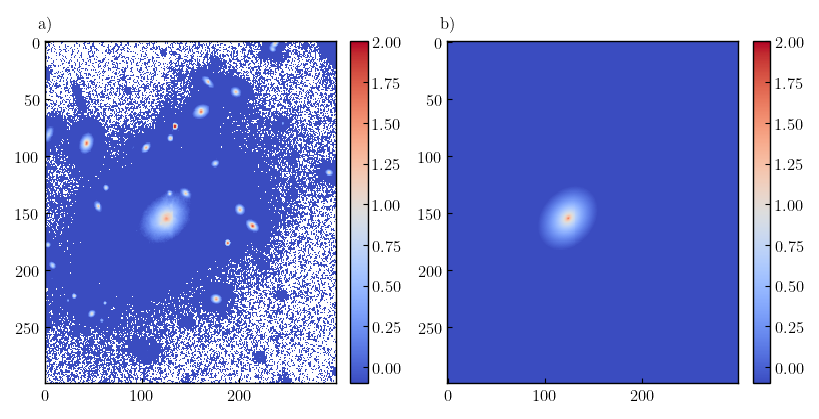

In [ ]:
import numpy as np
from astropy.modeling import models, fitting

sersic_init = models.Sersic2D(
    amplitude=1.0,
    r_eff=10.0,
    n=1.5,
    x_0=125.0, y_0=156.0,
    ellip=0.2,
    theta=0.0
)

data = fits.open("hst_12454_a2_wfc3_ir_f160w_ibt5a2_drz.fits")[1].data[500:800, 500:800] - 0.5

fitter = fitting.LevMarLSQFitter()
xi, yi = np.meshgrid(np.arange(data.shape[1]), np.arange(data.shape[0]))

best_fit_model = fitter(sersic_init, xi, yi, data)
fit_estimation = best_fit_model(xi, yi)

print(best_fit_model.param_names)
print(best_fit_model.parameters)

cmap_range = (-0.1, 2)
gl.SmartFigure(
    num_rows=1,
    num_cols=2,
    elements=[
        gl.Heatmap(np.log10(data), color_map_range=cmap_range),
        gl.Heatmap(np.log10(fit_estimation), color_map_range=cmap_range),
        # gl.Heatmap((data), color_map_range=cmap_range),
        # gl.Heatmap((fit_estimation), color_map_range=cmap_range),
    ],
    size=(8, 4)
).show()

In [68]:
semi_major_axis = best_fit_model.r_eff.value * 0.128
semi_minor_axis = semi_major_axis * (1 - best_fit_model.ellip.value)

print("semi-major axis (arcsec):", semi_major_axis)
print("semi-minor axis (arcsec):", semi_minor_axis)

semi-major axis (arcsec): 5.64473553173864
semi-minor axis (arcsec): 4.300920582577864


In [ ]:
prendre une image le plus proche du NIR et voir la surface brightness à un endroit spécifique
F160W : 16000 angstroms, 1.6 microns


In [74]:
from astropy import units as u

(10**(-18) * u.erg / u.s / u.cm**2).to(u.MJy / u.sr)

UnitConversionError: 'erg / (s cm2)' (energy flux/irradiance) and 'MJy / sr' (surface brightness) are not convertible

In [1]:
# 1.6 and 3.3 15 erg / s cm^2


2.8 * 1.52869447e-07 / (3.76e-14) * 1e-6

11.383894989361702